# Decision Tree - Bank Marketing

## Section 1: Theoretical Questions

### Question 1: What is a Decision Tree? Explain its structure (Root, Nodes, Leaves) with a real-life example.

-->

Answer:
A **Decision Tree** is a supervised machine learning algorithm that is used for both classification and regression. It works like a flowchart, where the data is split again and again based on questions about the features, until we reach a final answer.

The tree has three main parts. The **Root Node** is the top most node, and it contains the full dataset. The first and most important split happens here, on the feature that separates the data the best.

Next are the **Internal Nodes** (also called decision nodes). Each of these nodes asks a question on a feature, like "Is age > 30?", and the data goes left or right depending on the answer. The lines connecting the nodes are called **branches**.

Finally, the **Leaf Nodes** are the end points of the tree. They do not split further and they give the final prediction, like "Yes" or "No".

A simple real-life example is a bank deciding whether to give a loan. The root node may check "Is the credit score above 700?". If yes, the next node may check "Is the income above 50,000?", and if yes again, the leaf says **Approve**. If the credit score is low, it may directly go to a leaf that says **Reject**.

So a decision tree basically breaks a big decision into small simple yes/no questions, which also makes it very easy to understand and explain.

---
---

### Question 2: Differentiate between Gini Impurity and Entropy. Which one is used by default in Scikit-learn and why?

-->

Answer:
Gini Impurity and Entropy are both used to measure how **mixed or impure** a node is. The decision tree uses them to decide which feature and which split is the best at each step.

**Gini Impurity** tells the chance of wrongly classifying a randomly picked sample if we label it based on the class distribution of that node. The formula is **Gini = 1 - Σ(pᵢ²)**. Its value is 0 when the node is pure, and for two classes the maximum is 0.5.

**Entropy** comes from information theory and measures the amount of uncertainty or disorder in the node. The formula is **Entropy = -Σ pᵢ log₂(pᵢ)**. It is also 0 for a pure node, and for two classes the maximum is 1. When entropy is used, the tree chooses the split that gives the highest **Information Gain**, which is the reduction in entropy after the split.

The main difference is in calculation. Entropy uses **logarithms**, so it is a bit slower to compute, while Gini only uses squares so it is faster. In practice both give almost the same tree in most cases.

In Scikit-learn, the default criterion is **Gini** (`criterion='gini'`). This is mainly because it is computationally faster and gives very similar results to entropy, so it is a practical choice especially for large datasets.

---
---

### Question 3: What is Overfitting in Decision Trees? How can we detect it using training and testing accuracy?

-->

Answer:
**Overfitting** happens when the model learns the training data too well, including the noise and small random details, instead of learning the general pattern. Because of this it performs very well on training data but poorly on new data.

Decision trees are very likely to overfit. If we do not put any limit, the tree keeps splitting until every leaf is pure. In the end it almost memorises each training row, and the tree becomes very deep and complex.

We can detect overfitting by comparing the **training accuracy** and **testing accuracy**. If the training accuracy is very high (like 100%) but the testing accuracy is much lower (like 80%), there is a big gap, and that means the model is overfitting.

If both accuracies are high and close to each other, the model is generalising well. If both are low, then the model is **underfitting**, which means it is too simple to learn the pattern.

For example, in this assignment a tree with no depth limit gave **100% training accuracy** but only around **79.6% testing accuracy**, which is a clear sign of overfitting.

---
---

### Question 4: Explain Pruning in Decision Trees. What is the difference between Pre-pruning and Post-pruning?

-->

Answer:
**Pruning** is a technique used to reduce the size of a decision tree by removing the parts that are not very useful. The main goal is to reduce overfitting and make the tree simpler, so it works better on unseen data.

**Pre-pruning** (also called early stopping) stops the tree from growing too much while it is being built. We set some limits before training, such as **max_depth** (maximum levels of the tree), **min_samples_split** (minimum samples needed to split a node), **min_samples_leaf** or **max_leaf_nodes**. Once these limits are reached, the tree stops splitting.

**Post-pruning** works the other way. First the full tree is grown completely, and after that the branches that do not improve the performance much are cut off. In Scikit-learn this is done using **Cost Complexity Pruning** with the `ccp_alpha` parameter.

The main difference is the timing. Pre-pruning is applied **during** the building of the tree, so it is faster, but sometimes it may stop too early and miss a useful split. Post-pruning is applied **after** the full tree is built, so it takes more time but usually gives a better balanced tree.

In both cases the result is a smaller tree that is easier to read and less likely to overfit.

---
---

### Question 5: What is Feature Importance? How can it help businesses in decision-making?

-->

Answer:
**Feature Importance** tells us how much each input feature contributes to the predictions of the model. In a decision tree it is calculated based on how much a feature reduces the impurity (Gini or Entropy) across all the splits where it is used. All the importance values add up to 1.

A feature with a high importance score is used often in the tree and gives good splits, so it has a big effect on the final prediction. A feature with zero importance is not used by the tree at all.

For businesses this is very useful because it shows **what actually drives the outcome**. For example, if a bank finds that the outcome of the previous campaign is very important for whether a customer subscribes, it can first target customers who said yes earlier.

It also helps in **saving time and cost**. The company can focus its data collection and efforts only on the important factors and ignore the ones that do not matter much.

Another benefit is that it makes the model **easy to explain** to managers and non-technical people, because they can clearly see which factors the model is looking at.

So feature importance turns a model into practical business insights and helps in making better and data-driven decisions.

---
---

## Section 2: Practical Questions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

import warnings
warnings.filterwarnings('ignore')

### Question 6: Data Understanding

-->  

**Load the dataset**

In [2]:
df = pd.read_csv('bank.csv')

**Display first 5 rows**

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


**Check Shape, Data types and Column names**

In [4]:
print("Shape :", df.shape)

Shape : (11162, 17)


In [5]:
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
deposit        str
dtype: object

In [6]:
print("Column names :")
print(df.columns.tolist())

Column names :
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']


In [7]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical columns (", len(cat_cols), ") :", cat_cols)
print("Numerical columns (", len(num_cols), ") :", num_cols)

Categorical columns ( 10 ) : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']
Numerical columns ( 7 ) : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [8]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


Answer:
The Bank Marketing dataset was loaded using `pd.read_csv()`. It has **11162 rows and 17 columns**. Each row is one customer who was contacted in a bank's marketing campaign, and the target column **deposit** shows whether the customer subscribed to a term deposit (yes / no).

There are two types of variables in the data. The **numerical variables** (7 columns) are **age, balance, day, duration, campaign, pdays and previous**. These are stored as integers.

The **categorical variables** (10 columns) are **job, marital, education, default, housing, loan, contact, month, poutcome and deposit**. These are stored as text.

Among the categorical ones, some are **binary** (only yes/no), like default, housing, loan and deposit. Others have multiple categories, for example job has 12 different values and month has 12.

From `describe()` we can see that balance can be negative (min is -6847), which means some customers have an overdraft, and pdays has -1 which means the customer was not contacted before. These are valid values and not errors.

---
---

### Question 7: Data Cleaning

-->  

**Check for missing values**

In [9]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [10]:
# some columns use 'unknown' instead of blank
for col in cat_cols:
    count = (df[col] == 'unknown').sum()
    if count > 0:
        print(f"{col:10} unknown = {count}  ({count/len(df)*100:.2f}%)")

job        unknown = 70  (0.63%)
education  unknown = 497  (4.45%)
contact    unknown = 2346  (21.02%)
poutcome   unknown = 8326  (74.59%)


**Handle missing values (if any)**

In [11]:
# no actual null values, so nothing to fill
# 'unknown' is kept as its own category because it is a real response here
# (for example poutcome = unknown means the customer was never contacted before)
print("Total null values :", df.isnull().sum().sum())

Total null values : 0


**Check for duplicates**

In [12]:
print("Duplicate rows :", df.duplicated().sum())

Duplicate rows : 0


Answer:
First, `isnull().sum()` was used to check for missing values. The result shows **0 missing values** in all 17 columns. There were also **0 duplicate rows**, so no rows needed to be removed.

But while checking the categorical columns, I found that some of them use the word **"unknown"** instead of leaving it blank. **poutcome** has 8326 unknown values (about 74.6%), **contact** has 2346, **education** has 497 and **job** has 70.

I decided to **keep "unknown" as a separate category** instead of removing or replacing it. For poutcome, unknown simply means the customer was not part of any earlier campaign, so it is real information. For contact, unknown means the contact type was not recorded. If I drop these rows I would lose most of the data, and replacing them with the most common value could give wrong information.

So the dataset is quite clean. There are no nulls or duplicates, and the only issue is these "unknown" labels, which are handled by treating them as their own category.

---
---

### Question 8: Data Preprocessing

-->  

**Convert categorical variables into numerical**

In [13]:
# binary columns -> 1 / 0
binary_cols = ['default', 'housing', 'loan', 'deposit']
for col in binary_cols:
    df[col] = df[col].map({'yes': 1, 'no': 0})

df[binary_cols].head()

,default,housing,loan,deposit
0,0,1,0,1
1,0,0,0,1
2,0,1,0,1
3,0,1,0,1
4,0,0,0,1


In [14]:
# multi category columns -> one hot encoding
multi_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
df = pd.get_dummies(df, columns=multi_cols, drop_first=True, dtype=int)

print("Shape after encoding :", df.shape)
df.head()

Shape after encoding : (11162, 43)


,age,default,balance,housing,loan,day,duration,campaign,pdays,previous,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,59,0,2343,1,0,5,1042,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
1,56,0,45,0,0,5,1467,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
2,41,0,1270,1,0,5,1389,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
3,55,0,2476,1,0,5,579,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
4,54,0,184,0,0,5,673,2,-1,0,...,0,0,0,1,0,0,0,0,0,1


Answer:
Two encoding methods were used here.

For the binary columns (**default, housing, loan and deposit**), I used simple **mapping / label encoding**, where **yes = 1 and no = 0**. Since these have only two values, one column is enough.

For the columns with more than two categories (**job, marital, education, contact, month and poutcome**), I used **One-Hot Encoding** with `pd.get_dummies()`. This creates a new 0/1 column for each category. I used **drop_first=True** to remove one column from each group because its value can be understood from the others. After encoding, the number of columns went from **17 to 43**.

Encoding is necessary because the Decision Tree in Scikit-learn **only works with numbers**. It cannot directly read text like "married" or "management", and it will give an error if we pass text data.

One-hot encoding was chosen instead of plain label encoding for these columns because label encoding would give numbers like 0, 1, 2, 3 to jobs, and the model might think there is some order between them, which is not true. One-hot keeps every category separate and also makes the feature importance easy to read, like **poutcome_success** or **month_mar**.

---
---

### Question 9: Feature Selection & Splitting

-->  

**Separate Features (X) and Target (y)**

In [15]:
X = df.drop(columns='deposit')
y = df['deposit']

print("X shape :", X.shape)
print("y shape :", y.shape)

X shape : (11162, 42)
y shape : (11162,)


**Perform train-test split (80-20)**

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print()
print("Train 'yes' ratio :", round(y_train.mean(), 3))
print("Test 'yes' ratio  :", round(y_test.mean(), 3))

X_train : (8929, 42)
X_test  : (2233, 42)

Train 'yes' ratio : 0.474
Test 'yes' ratio  : 0.474


Answer:
The data was divided into **X (features)**, which has all 42 input columns, and **y (target)**, which is the deposit column.

Then it was split in an **80-20 ratio** using `train_test_split()`. The training set has **8929 rows** and the testing set has **2233 rows**. I used **stratify=y** so that both sets have the same proportion of yes and no (around 47% yes in both), and **random_state=42** so the result stays the same every time.

Train-test split is important because we need to check how the model performs on **data it has never seen before**. If we test the model on the same data it was trained on, it will look very good but that does not mean it will work in real life.

The test set acts like new customers. It gives an honest idea of the real performance and also helps us find out whether the model is **overfitting**, by comparing training and testing accuracy.

---
---

### Question 10: Model Building

-->  

In [17]:
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

print("Tree depth :", dt_model.get_depth())
print("Number of leaves :", dt_model.get_n_leaves())

Tree depth : 5
Number of leaves : 30


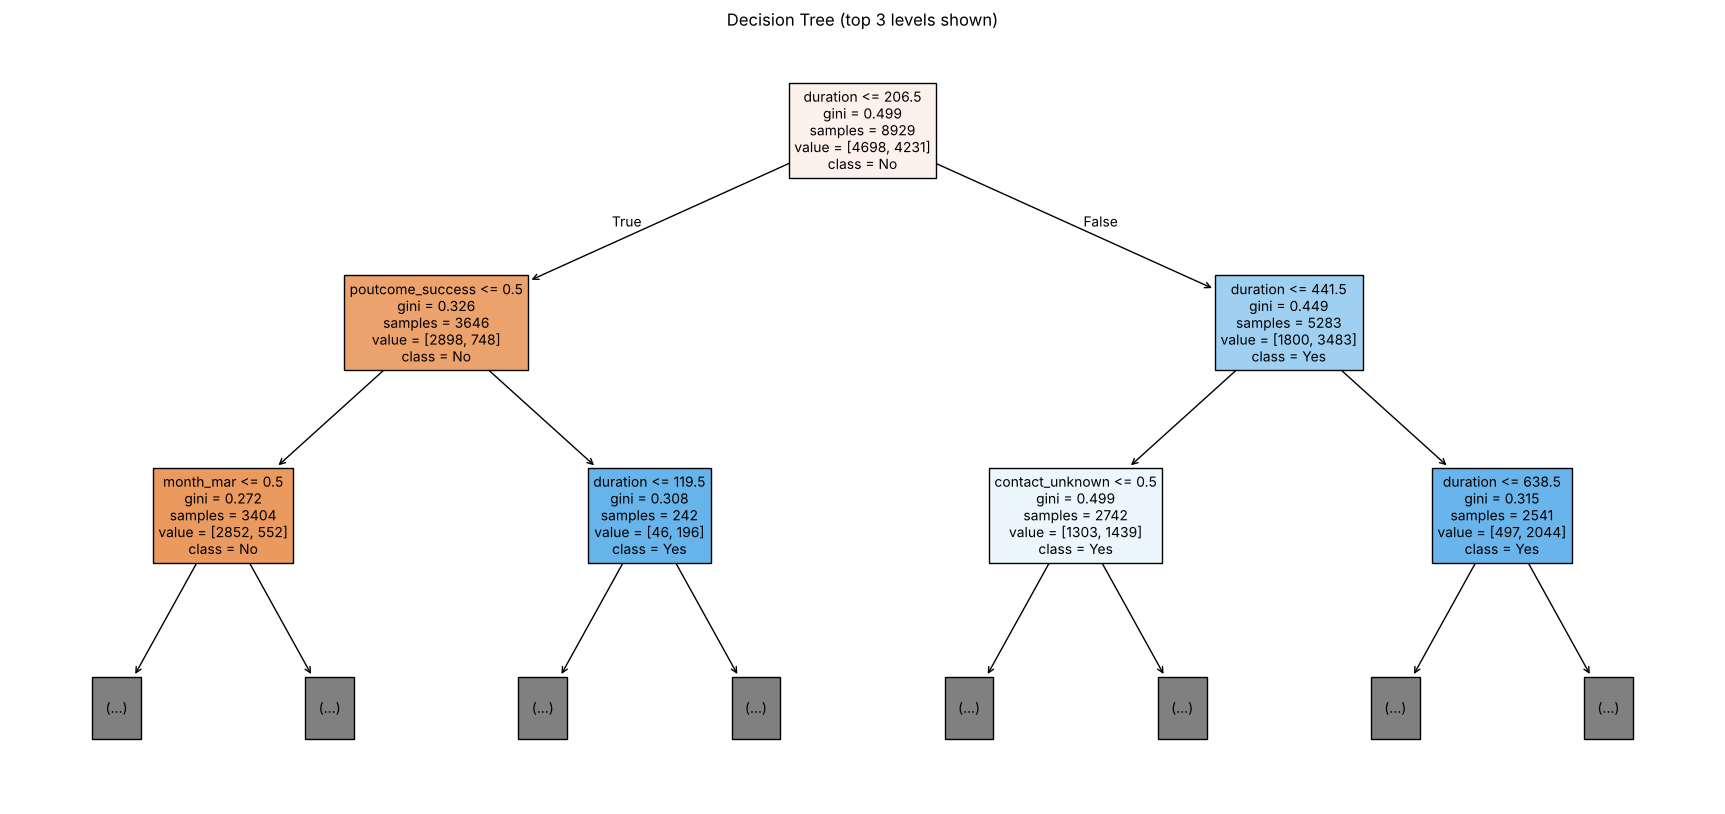

In [18]:
plt.figure(figsize=(22,10))
plot_tree(dt_model, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, max_depth=2, fontsize=10)
plt.title('Decision Tree (top 3 levels shown)')
plt.show()

Answer:
A Decision Tree Classifier was trained using **criterion='gini'** and **max_depth=5**. Gini means the tree uses Gini Impurity to choose the best split at every node.

**max_depth** controls the **maximum number of levels** the tree can grow from the root to the leaf. With max_depth=5, any path in the tree can have at most 5 questions before it reaches a final decision. Our tree has depth 5 and **30 leaf nodes**.

If max_depth is too large or not set, the tree keeps splitting until it memorises the training data, which causes **overfitting**. If it is too small, the tree becomes too simple and cannot learn the patterns properly, which causes **underfitting**.

So max_depth is one of the most important settings to control the complexity of the tree, and it is a type of **pre-pruning**.

From the tree plot we can see that the root node splits on **duration**, which means call duration is the first and most important factor the model looks at.

---
---

### Question 11: Model Evaluation

-->  

**Accuracy score**

In [19]:
y_pred = dt_model.predict(X_test)
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))

Accuracy : 0.803


**Confusion Matrix**

[[945 230]
 [210 848]]


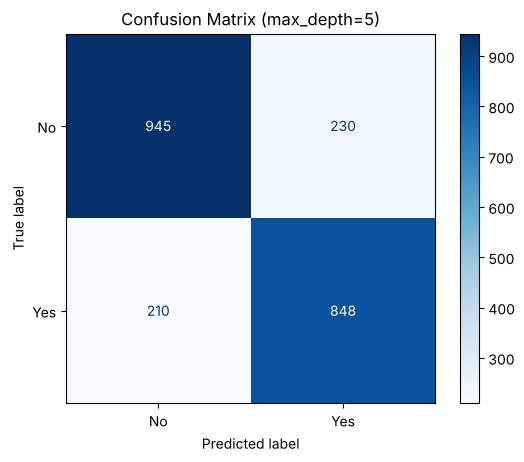

In [20]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=['No', 'Yes']).plot(cmap='Blues')
plt.title('Confusion Matrix (max_depth=5)')
plt.show()

**Classification Report**

In [21]:
print(classification_report(y_test, y_pred, target_names=['No', 'Yes']))

              precision    recall  f1-score   support

          No       0.82      0.80      0.81      1175
         Yes       0.79      0.80      0.79      1058

    accuracy                           0.80      2233
   macro avg       0.80      0.80      0.80      2233
weighted avg       0.80      0.80      0.80      2233



deposit
0    5873
1    5289
Name: count, dtype: int64

deposit
0    52.62
1    47.38
Name: proportion, dtype: float64


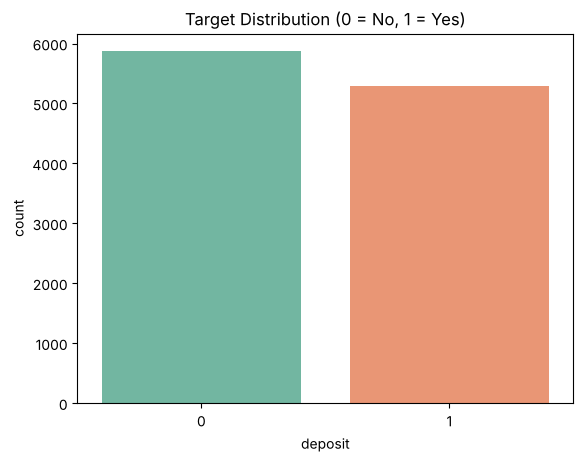

In [22]:
print(y.value_counts())
print()
print((y.value_counts(normalize=True) * 100).round(2))

sns.countplot(x=y, palette='Set2')
plt.title('Target Distribution (0 = No, 1 = Yes)')
plt.show()

Answer:
The model gives an **accuracy of about 80.3%** on the test data, which means it correctly predicted 1793 out of 2233 customers.

From the confusion matrix, **945** customers who said no were correctly predicted as no, and **848** customers who said yes were correctly predicted as yes. The model made **230 false positives** (predicted yes but actually no) and **210 false negatives** (predicted no but actually yes).

**Precision** tells us, out of all the customers the model predicted as yes, how many actually said yes. For the yes class precision is **0.79**, so 79% of the people the model picks for a call will really subscribe.

**Recall** tells us, out of all the customers who actually said yes, how many the model was able to find. For the yes class recall is **0.80**, so the model catches 80% of the real subscribers. For the no class, precision is 0.82 and recall is 0.80.

Regarding **class imbalance**, the dataset has **5873 no (52.6%)** and **5289 yes (47.4%)**. This is almost balanced, so there is **no major imbalance problem** here. That is also why the precision and recall are similar for both classes.

So overall the model is **performing well**. It is balanced for both classes and an accuracy of around 80% is good for a simple tree with depth 5.

---
---

### Question 12: Overfitting Check

-->  

In [23]:
train_acc = accuracy_score(y_train, dt_model.predict(X_train))
test_acc = accuracy_score(y_test, dt_model.predict(X_test))

print("Training Accuracy :", round(train_acc, 4))
print("Testing Accuracy  :", round(test_acc, 4))
print("Difference        :", round(train_acc - test_acc, 4))

Training Accuracy : 0.8077
Testing Accuracy  : 0.803
Difference        : 0.0047


In [24]:
# for comparison - tree with no depth limit
full_tree = DecisionTreeClassifier(criterion='gini', random_state=42)
full_tree.fit(X_train, y_train)

print("Full tree depth   :", full_tree.get_depth())
print("Training Accuracy :", round(accuracy_score(y_train, full_tree.predict(X_train)), 4))
print("Testing Accuracy  :", round(accuracy_score(y_test, full_tree.predict(X_test)), 4))

Full tree depth   : 30
Training Accuracy : 1.0
Testing Accuracy  : 0.7962


Answer:
For the max_depth=5 model, the **training accuracy is about 80.8%** and the **testing accuracy is about 80.3%**. The difference is only around **0.5%**.

Since both accuracies are very close, the model is **not overfitting**. It is giving almost the same performance on new data as it gives on training data, which means it has learned the general pattern and not memorised the rows.

It is also **not underfitting**, because 80% is a decent accuracy for this problem. If it was underfitting, both accuracies would be low.

To compare, I also trained a tree with **no depth limit**. That tree gave **100% training accuracy** but only about **79.6% testing accuracy**. This big gap shows clear overfitting. So setting max_depth=5 actually helped the model to generalise better, and it even gave a slightly better test accuracy than the full tree.

So the max_depth=5 model is a **good fit**.

---
---

### Question 13: Pruning Experiment

-->  

In [25]:
pruned_model = DecisionTreeClassifier(criterion='gini', max_depth=3, min_samples_split=20, random_state=42)
pruned_model.fit(X_train, y_train)

y_pred_pruned = pruned_model.predict(X_test)

print("Training Accuracy :", round(accuracy_score(y_train, pruned_model.predict(X_train)), 4))
print("Testing Accuracy  :", round(accuracy_score(y_test, y_pred_pruned), 4))
print()
print(confusion_matrix(y_test, y_pred_pruned))
print()
print(classification_report(y_test, y_pred_pruned, target_names=['No', 'Yes']))

Training Accuracy : 0.7786
Testing Accuracy  : 0.7801

[[812 363]
 [128 930]]

              precision    recall  f1-score   support

          No       0.86      0.69      0.77      1175
         Yes       0.72      0.88      0.79      1058

    accuracy                           0.78      2233
   macro avg       0.79      0.79      0.78      2233
weighted avg       0.80      0.78      0.78      2233



In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score

compare = pd.DataFrame({
    'Model': ['max_depth=5', 'max_depth=3, min_samples_split=20'],
    'Train Accuracy': [accuracy_score(y_train, dt_model.predict(X_train)), accuracy_score(y_train, pruned_model.predict(X_train))],
    'Test Accuracy': [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_pruned)],
    'Precision (Yes)': [precision_score(y_test, y_pred), precision_score(y_test, y_pred_pruned)],
    'Recall (Yes)': [recall_score(y_test, y_pred), recall_score(y_test, y_pred_pruned)],
    'F1 (Yes)': [f1_score(y_test, y_pred), f1_score(y_test, y_pred_pruned)],
    'Leaves': [dt_model.get_n_leaves(), pruned_model.get_n_leaves()]
}).round(4)
compare

,Model,Train Accuracy,Test Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),Leaves
0,max_depth=5,0.8077,0.8030,0.7866,0.8015,0.7940,30
1,"max_depth=3, min_samples_split=20",0.7786,0.7801,0.7193,0.8790,0.7912,8


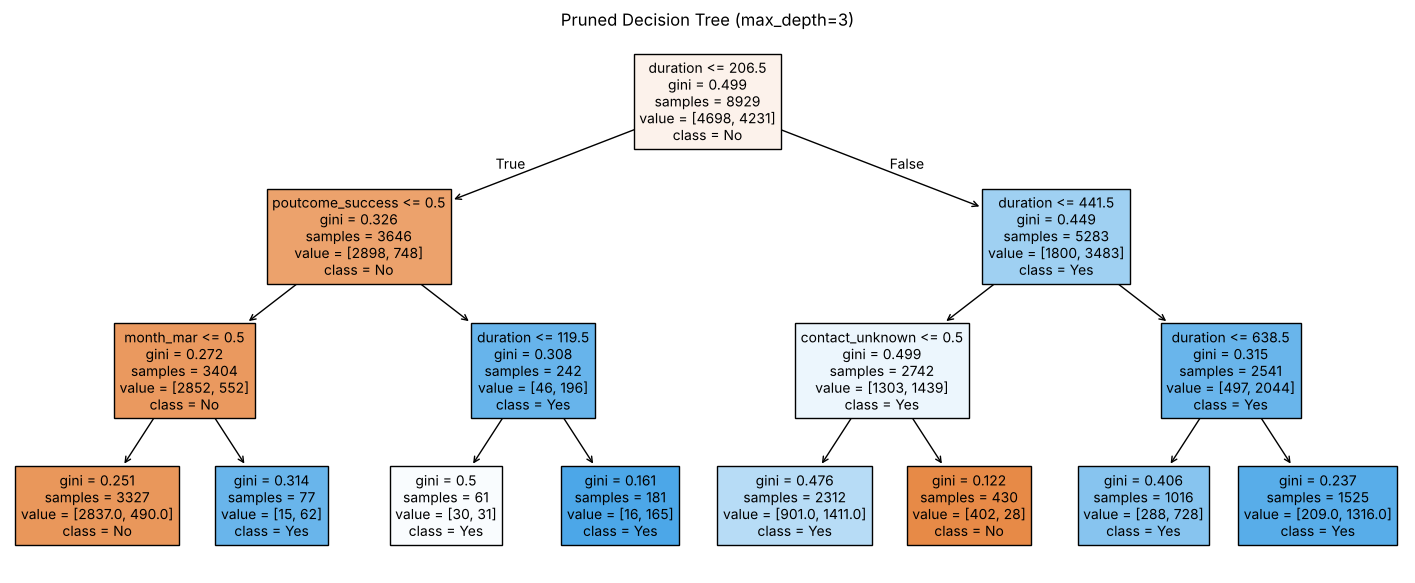

In [27]:
plt.figure(figsize=(18,7))
plot_tree(pruned_model, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.title('Pruned Decision Tree (max_depth=3)')
plt.show()

Answer:
A second model was trained with **max_depth=3** and **min_samples_split=20**. This is a more pruned and simpler tree, with only **8 leaf nodes** compared to 30 in the first model.

The pruned model gives a **training accuracy of about 77.9%** and a **testing accuracy of about 78.0%**. Both are almost the same, so this model also does not overfit at all.

When compared with the first model (max_depth=5), the test accuracy dropped from **80.3% to 78.0%**. There is also a change in how it predicts. The pruned model has a higher **recall for yes (0.88)** but a lower **precision for yes (0.72)**. This means it predicts yes for more people, so it catches more real subscribers but also makes more wrong yes predictions (363 false positives vs 230 before).

Overall, I think the **max_depth=5 model is better**. It has higher accuracy and F1 score, it is more balanced between precision and recall, and it still does not overfit. The depth 3 tree is a little too simple and starts to slightly **underfit**.

But the pruned tree is much easier to read and explain. If the bank's main goal is to not miss any possible customer, the higher recall of the pruned model could also be useful.

---
---

### Question 14: Feature Importance

-->  

**Extract top 5 important features**

In [28]:
importance = pd.DataFrame({'Feature': X.columns, 'Importance': dt_model.feature_importances_})
importance = importance.sort_values(by='Importance', ascending=False).reset_index(drop=True)

top5 = importance.head(5)
top5

,Feature,Importance
0,duration,0.606823
1,poutcome_success,0.159491
2,contact_unknown,0.141774
3,housing,0.036379
4,month_mar,0.032763


**Plot feature importance graph**

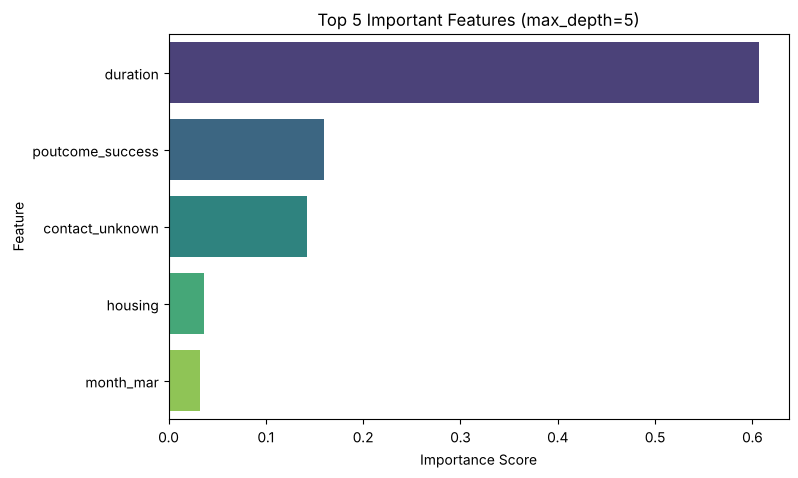

In [29]:
plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=top5, palette='viridis')
plt.title('Top 5 Important Features (max_depth=5)')
plt.xlabel('Importance Score')
plt.show()

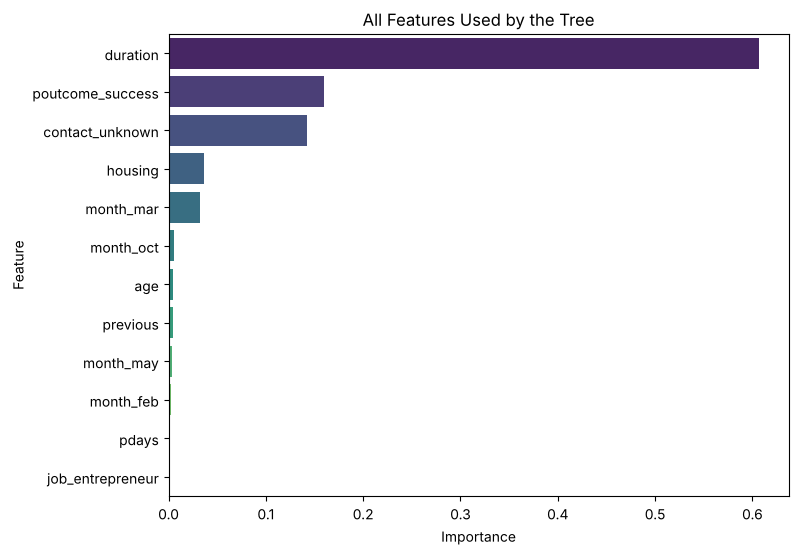

In [30]:
plt.figure(figsize=(8,6))
sns.barplot(x='Importance', y='Feature', data=importance[importance['Importance'] > 0], palette='viridis')
plt.title('All Features Used by the Tree')
plt.show()

Answer:
The feature importance was taken from the max_depth=5 model using `feature_importances_`. The top 5 features are:

**1. duration (0.607)** - this is the length of the last call in seconds and it is by far the most important feature. It alone gives more than 60% of the importance.
**2. poutcome_success (0.159)** - whether the customer said yes in the previous campaign.
**3. contact_unknown (0.142)** - whether the contact type of the customer is unknown.
**4. housing (0.036)** - whether the customer has a housing loan.
**5. month_mar (0.033)** - whether the customer was contacted in March.

These five features together make up about **97.7%** of the total importance, so the model mostly depends on them. Many other features like job, marital status and education have very little or zero importance in this tree.

**duration** has a strong effect because when a customer is interested, the call naturally goes longer. **poutcome_success** shows that people who subscribed before are very likely to do it again. **contact_unknown** has a negative effect, these customers say yes much less often.

One thing to note is that duration is only known **after** the call is finished, so in a real situation it cannot be used to decide whom to call. It is still useful to understand customer behaviour.

---
---

### Question 15: Business Insights

-->  

In [31]:
raw = pd.read_csv('bank.csv')
raw['yes'] = (raw['deposit'] == 'yes').astype(int)

print("Subscription rate by previous outcome (%)")
print((raw.groupby('poutcome')['yes'].mean() * 100).round(2))
print()
print("Subscription rate by contact type (%)")
print((raw.groupby('contact')['yes'].mean() * 100).round(2))
print()
print("Subscription rate by housing loan (%)")
print((raw.groupby('housing')['yes'].mean() * 100).round(2))

Subscription rate by previous outcome (%)
poutcome
failure    50.33
other      57.17
success    91.32
unknown    40.67
Name: yes, dtype: float64

Subscription rate by contact type (%)
contact
cellular     54.33
telephone    50.39
unknown      22.59
Name: yes, dtype: float64

Subscription rate by housing loan (%)
housing
no     57.03
yes    36.64
Name: yes, dtype: float64


In [32]:
print("Subscription rate by call duration (%)")
print((raw.groupby(pd.cut(raw['duration'], [0, 180, 300, 600, 5000], labels=['0-3 min', '3-5 min', '5-10 min', '10+ min']))['yes'].mean() * 100).round(2))
print()
print("Subscription rate by age group (%)")
print((raw.groupby(pd.cut(raw['age'], [0, 25, 35, 60, 100], labels=['18-25', '26-35', '36-60', '60+']))['yes'].mean() * 100).round(2))

Subscription rate by call duration (%)
duration
0-3 min     18.01
3-5 min     46.10
5-10 min    61.55
10+ min     85.18
Name: yes, dtype: float64

Subscription rate by age group (%)
age
18-25    71.11
26-35    47.67
36-60    42.04
60+      82.16
Name: yes, dtype: float64


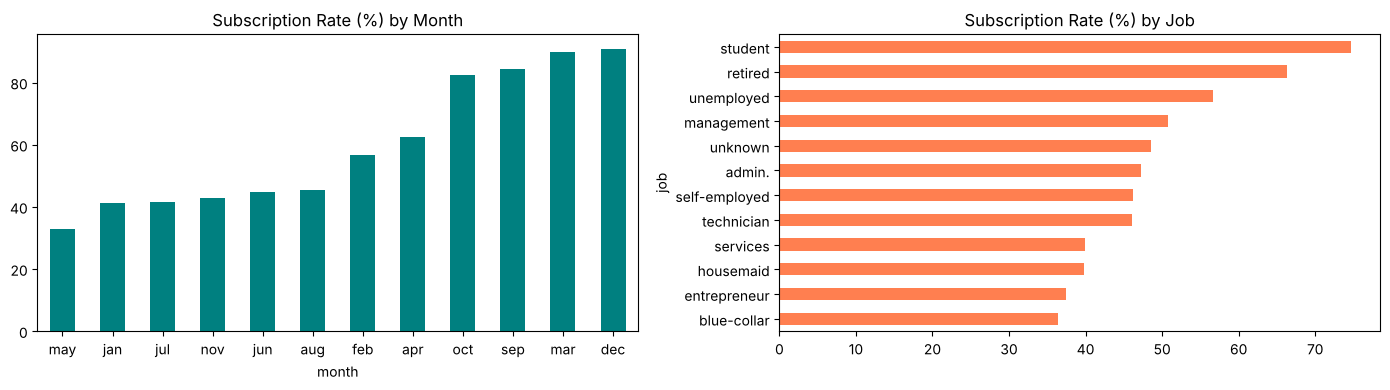

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))

(raw.groupby('month')['yes'].mean() * 100).sort_values().plot(kind='bar', color='teal', ax=ax[0])
ax[0].set_title('Subscription Rate (%) by Month')
ax[0].tick_params(axis='x', rotation=0)

(raw.groupby('job')['yes'].mean() * 100).sort_values().plot(kind='barh', color='coral', ax=ax[1])
ax[1].set_title('Subscription Rate (%) by Job')

plt.tight_layout()
plt.show()

Answer:
Based on the model and the feature importance, we can clearly see which customers are more likely to say "yes" to a term deposit.

**Which type of customers are more likely to say "yes"?**
First, customers who **said yes in the previous campaign** are the best target. About **91% of them subscribed again**, compared to only around 41% of customers who were never contacted before.

Another group is customers with **longer call duration**. People who stayed on the call for more than 10 minutes subscribed about **85%** of the time, while calls under 3 minutes had only around **18%** success. Long calls show real interest.

Customers who were contacted on **cellular phones** (54% yes) do much better than those with **unknown contact type** (only about 23%). Customers **without a housing loan** also say yes more often (57%) than those with a housing loan (37%), probably because they have more money free to save.

By age and job, **students and retired people** are the most likely to subscribe (about 75% and 66%). Customers **above 60** have around **82%** yes and people under 25 around **71%**. Blue-collar workers have the lowest rate at around 36%.

The month also matters. Campaigns in **March, September, October and December** had over **80% success**, while **May** had the lowest at only about **33%**, even though the most calls were made in May.

**What strategy should a bank use?**
The bank should first **target past subscribers** and give them priority, because they are the easiest to convert. It should also focus more on **students, retired people and customers above 60**, and on customers without existing housing loans.

The bank should **collect proper contact details** and prefer mobile phones, because "unknown" contact customers rarely say yes. Call agents should be trained to have **longer, more engaging conversations**, since interest builds during longer calls.

Finally, the bank should **plan big campaigns in March, September, October and December** instead of putting most of the effort in May. This way it can spend less on calls and still get more deposits.